# 第 3 章 伪随机数 — 代码实验

对照教材：Dunn & Shultis《Exploring Monte Carlo Methods》Ch.3（主线）；Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》§1.3 与附录 A。

约定：确定性生成器使用各自的种子（保证可复现）；NumPy 的 `default_rng(2024)` 仅作现代生成器对照。实跑图保存到 `docs/mc/images/ch03/`，编号 `out-3-M` 与笔记图注一一对应。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import math

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch03")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2024)   # 全章共用随机流（现代生成器的对照）
print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 平方取中：归零与短周期（S&M §1.3.2）

取 4 位种子，平方后左侧补零到 8 位、抽中间 4 位作下一个数（冯·诺依曼，1940 年代）。两个死穴：**掉进 0（或某个不动点）出不来**；**周期极短**。先逐种子追踪，再对全部 10000 个种子做"命运普查"。

In [2]:
def middle_square(seed, digits=4):
    x, seq, seen = seed, [seed], {seed}
    while True:
        s = f"{x * x:0{2*digits}d}"                  # 平方，左侧补零到 2d 位
        x = int(s[digits//2 : digits//2 + digits])   # 抽中间 d 位
        if x in seen:                                # 状态重复 → 环闭合
            seq.append(x)
            return seq
        seq.append(x)
        seen.add(x)

for s in (1234, 4353, 1000, 3792, 6100):
    seq = middle_square(s)
    L = len(seq) - 1 - seq.index(seq[-1])            # 进入环的长度
    print(f"种子 {s:4d}: {' -> '.join(map(str, seq[:8]))} ...  步数 {len(seq)-1}，环长 {L}（环值 {seq[-1]}）")

种子 1234: 1234 -> 5227 -> 3215 -> 3362 -> 3030 -> 1809 -> 2724 -> 4201 ...  步数 57，环长 1（环值 0）
种子 4353: 4353 -> 9486 -> 9841 -> 8452 -> 4363 -> 357 -> 1274 -> 6230 ...  步数 69，环长 4（环值 6100）
种子 1000: 1000 -> 0 -> 0 ...  步数 2，环长 1（环值 0）
种子 3792: 3792 -> 3792 ...  步数 1，环长 1（环值 3792）
种子 6100: 6100 -> 2100 -> 4100 -> 8100 -> 6100 ...  步数 4，环长 4（环值 6100）


In [3]:
fates, n_to0, n_fix = {}, 0, 0
for seed in range(10000):
    seq = middle_square(seed)
    L = len(seq) - 1 - seq.index(seq[-1])
    fates[L] = fates.get(L, 0) + 1
    if seq[-1] == 0:
        n_to0 += 1
    elif L == 1:
        n_fix += 1
print(f"10000 个种子：掉进 0 的 {n_to0} 个，非零不动点 {n_fix} 个，其余进入短环")
print("环长分布 {环长: 种子数}:", dict(sorted(fates.items())))

10000 个种子：掉进 0 的 1968 个，非零不动点 295 个，其余进入短环
环长分布 {环长: 种子数}: {1: 2263, 4: 7737}


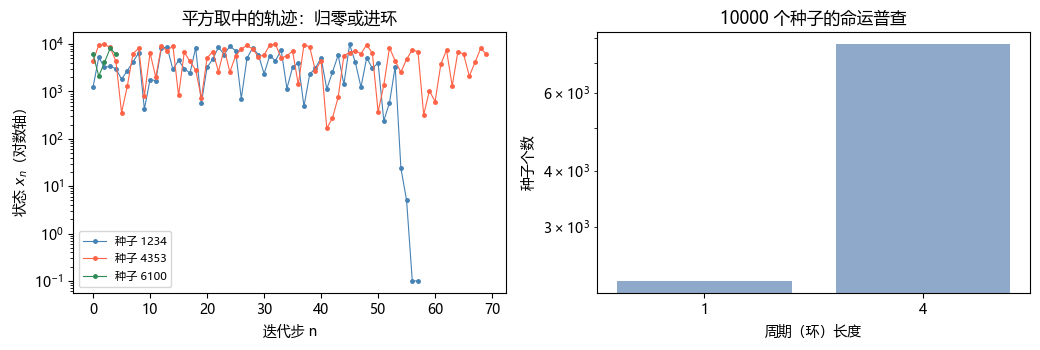

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
for s, c in zip((1234, 4353, 6100), ("steelblue", "tomato", "seagreen")):
    seq = middle_square(s)                     # 画全程：直到归零或环闭合
    ax[0].semilogy(range(len(seq)), np.maximum(seq, 0.1), "o-", ms=2.5, lw=0.8, color=c, label=f"种子 {s}")
ax[0].set_xlabel("迭代步 n"); ax[0].set_ylabel("状态 $x_n$（对数轴）")
ax[0].legend(fontsize=8); ax[0].set_title("平方取中的轨迹：归零或进环")
labels = sorted(fates)
ax[1].bar([str(L) for L in labels], [fates[L] for L in labels], color="#8ea9c9")
ax[1].set_yscale("log")
ax[1].set_xlabel("周期（环）长度"); ax[1].set_ylabel("种子个数")
ax[1].set_title("10000 个种子的命运普查")
fig.tight_layout(); save(fig, "out-3-1.png"); plt.show()

## 实验 2 LCG 满周期三判据（Hull–Dobell）与原根（D&S §3.1 + S&M §1.3.3）

$x_{n+1}=(a x_n + c) \bmod m$。定理（$c\ne 0$）：对每个种子周期都等于 $m$，当且仅当
① $\gcd(c,m)=1$；② 对每个整除 $m$ 的素数 $p$，$p \mid (a-1)$；③ 若 $4 \mid m$ 则 $4 \mid (a-1)$。

取 $m=16$：$a=5, c=1$ 三条全满足 → 周期 16；$a=3, c=1$ 违反③ → 周期 8；$a=5, c=2$ 违反① → 周期 8。
再验证乘同余（$c=0$）的满周期条件：$m=2^{31}-1$，$a=16807=7^5$ 是模 $m$ 的原根 → 周期 $m-1$；对照 RANDU（$a=65539, m=2^{31}$）周期只有 $2^{29}$。

In [5]:
def lcg_period(a, c, m, seed):
    x, t = (a * seed + c) % m, 1
    while x != seed:
        x = (a * x + c) % m
        t += 1
    return t

for a, c, m, tag in [(5, 1, 16, "满足①②③"), (3, 1, 16, "违反③（4|m 但 4 不整除 a−1）"),
                     (5, 2, 16, "违反①（gcd(c,m)=2）")]:
    ps = {lcg_period(a, c, m, s) for s in range(m)}
    print(f"a={a}, c={c}, m={m}: {tag} -> 各种子周期 = {ps}")

a=5, c=1, m=16: 满足①②③ -> 各种子周期 = {16}
a=3, c=1, m=16: 违反③（4|m 但 4 不整除 a−1） -> 各种子周期 = {8}
a=5, c=2, m=16: 违反①（gcd(c,m)=2） -> 各种子周期 = {8}


In [6]:
# 乘同余满周期：a 是素数模的原根 <=> 周期 m−1
m = 2**31 - 1                      # 梅森素数 2147483647
n, ps = m - 1, []                  # 分解 m − 1 = 2^31 − 2 的素因数
f = 2
while f * f <= n:
    if n % f == 0:
        ps.append(f)
        while n % f == 0:
            n //= f
    f += 1
if n > 1:
    ps.append(n)
print(f"m − 1 = 2^31 − 2 的素因数: {ps}")
a = 16807                          # minstd 的乘子 = 7^5
is_proot = all(pow(a, (m - 1) // p, m) != 1 for p in ps)
print(f"a = 16807: 对每个素因数 p 都有 a^((m−1)/p) mod m ≠ 1 → 原根 → 周期 = m−1 = {m-1 if is_proot else '?'}")

# 对照 RANDU：m = 2^31（2 的幂），阶只有 2^29
ok29 = (pow(65539, 2**29, 2**31) == 1) and (pow(65539, 2**28, 2**31) != 1)
print(f"RANDU（a=65539, m=2^31, 奇种子）: 周期 = 2^29 = {2**29}（验证 {ok29}）")

m − 1 = 2^31 − 2 的素因数: [2, 3, 7, 11, 31, 151, 331]
a = 16807: 对每个素因数 p 都有 a^((m−1)/p) mod m ≠ 1 → 原根 → 周期 = m−1 = 2147483646
RANDU（a=65539, m=2^31, 奇种子）: 周期 = 2^29 = 536870912（验证 True）


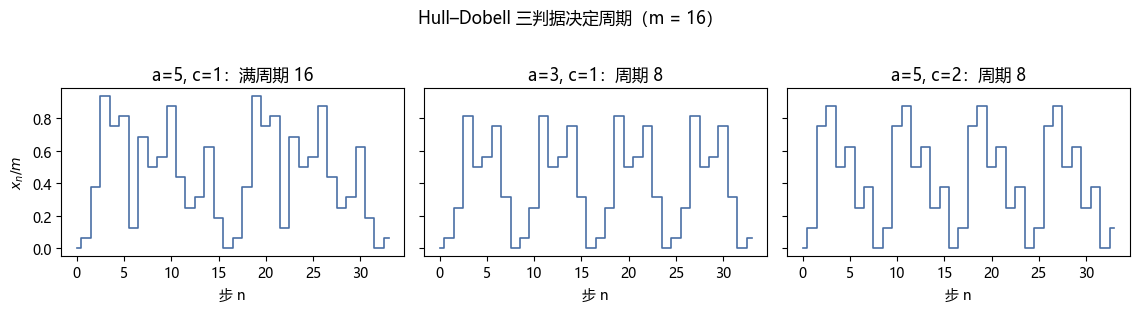

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.0), sharey=True)
for k, (a, c, m, tag) in enumerate([(5, 1, 16, "a=5, c=1：满周期 16"),
                                    (3, 1, 16, "a=3, c=1：周期 8"),
                                    (5, 2, 16, "a=5, c=2：周期 8")]):
    x, seq = 0, []
    for _ in range(34):
        seq.append(x / m)
        x = (a * x + c) % m
    ax[k].step(range(len(seq)), seq, where="mid", lw=1.2, color="#4a6fa5")
    ax[k].set_title(tag); ax[k].set_xlabel("步 n")
ax[0].set_ylabel("$x_n / m$")
fig.suptitle("Hull–Dobell 三判据决定周期（m = 16）", y=1.03)
fig.tight_layout(); save(fig, "out-3-2.png"); plt.show()

## 实验 3 生成数的结构：二维散点图（D&S §3.2）

把相邻数对 $(x_n, x_{n+1})$ 当平面坐标（整数坐标 $[0,29]^2$）画出来——线性同余的点永远落在若干条平行直线上（Marsaglia 1968："随机数主要躺在平面上"）。
对照 $m=29$ 的两个满周期乘子：$a=3$（斜率 3 的 3 条线）与 $a=8$（6 条与 7 条两个方向、间距相近），以及 minstd 的大样本。
直线族条数的数法：点满足 $x_{n+1}=a x_n - k m$（$k$ 整数），故 $x_{n+1}-a x_n$ 只能取 $m$ 的整数倍——不同倍数的个数 = 直线条数。

In [8]:
def lcg_u(a, m, seed, n):
    x, out = seed, np.empty(n)
    for i in range(n):
        x = (a * x) % m
        out[i] = x / m
    return out

def count_lines(xi, p, q, m):
    """直线族 p·x_{n+1} + q·x_n = 常数（常数必为 m 的倍数）的条数"""
    w = p * xi[1:] + q * xi[:-1]
    return len(np.unique(w // m))

for a in (3, 8):
    xs = lcg_u(a, 29, 1, 29)
    xi = (np.round(xs * 29)).astype(int)     # 恢复整数状态
    if a == 3:
        print(f"a=3: 斜率 3 的直线 {count_lines(xi, 1, -3, 29)} 条；斜率 −2/9 的直线 {count_lines(xi, 9, 2, 29)} 条")
    else:
        print(f"a=8: 斜率 3/4 的直线 {count_lines(xi, 4, -3, 29)} 条；斜率 −5/3 的直线 {count_lines(xi, 3, 5, 29)} 条")

a=3: 斜率 3 的直线 3 条；斜率 −2/9 的直线 10 条
a=8: 斜率 3/4 的直线 6 条；斜率 −5/3 的直线 7 条


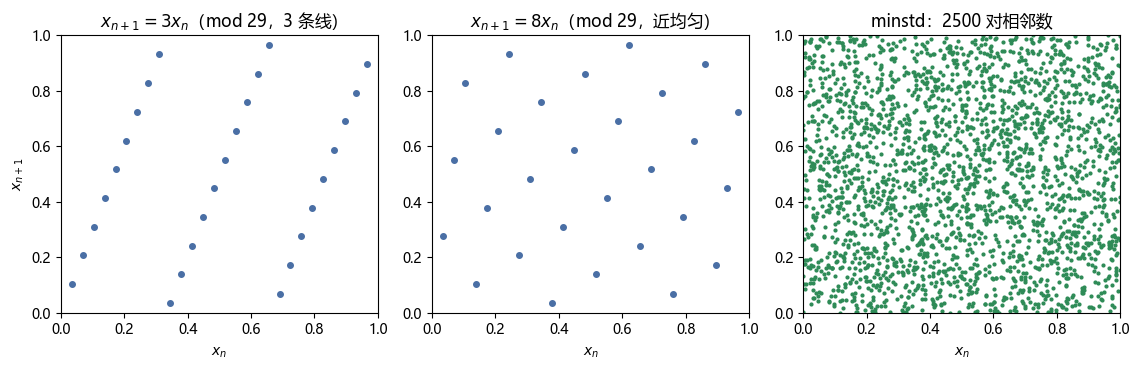

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.8))
u3 = lcg_u(3, 29, 1, 29)
u8 = lcg_u(8, 29, 1, 29)
for k, (u, tag) in enumerate([(u3, "$x_{n+1}=3x_n$（mod 29，3 条线）"),
                              (u8, "$x_{n+1}=8x_n$（mod 29，近均匀）")]):
    ax[k].plot(u[:-1], u[1:], "o", ms=4, color="#4a6fa5")
    ax[k].set_xlim(0, 1); ax[k].set_ylim(0, 1)
    ax[k].set_title(tag); ax[k].set_xlabel("$x_n$")
ax[0].set_ylabel("$x_{n+1}$")
u_m = lcg_u(16807, 2**31 - 1, 1, 2500)
ax[2].plot(u_m[:-1], u_m[1:], "o", ms=2, color="seagreen")
ax[2].set_xlim(0, 1); ax[2].set_ylim(0, 1)
ax[2].set_title("minstd：2500 对相邻数"); ax[2].set_xlabel("$x_n$")
fig.tight_layout(); save(fig, "out-3-3.png"); plt.show()

## 实验 4 RANDU：15 张平面（D&S §3.4）

RANDU：$x_{n+1}=65539\,x_n \bmod 2^{31}$。恒等式 $x_{n+2}-6x_{n+1}+9x_n\equiv 0 \pmod{2^{31}}$（逐行推导见笔记）迫使所有三维点 $(x_n,x_{n+1},x_{n+2})$ 落在 15 张平行平面 $9x_n-6x_{n+1}+x_{n+2}=c\,2^{31}$ 上。三维散点 + 投影直方图实锤，对照 minstd。

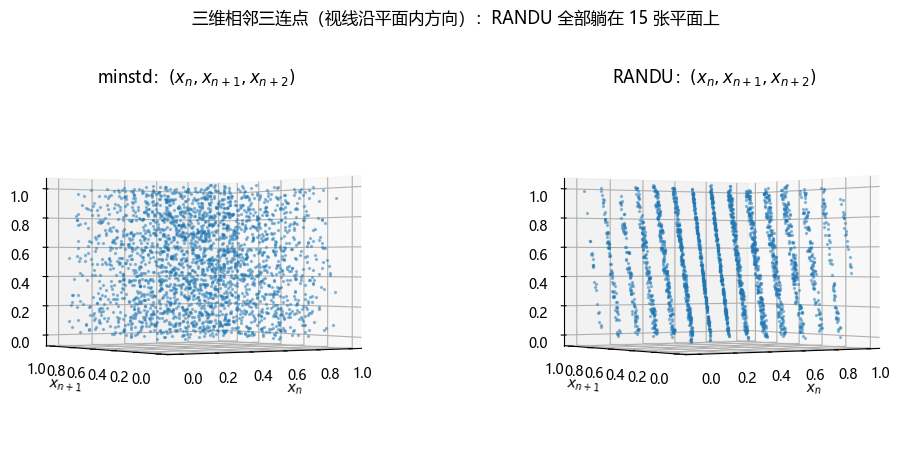

In [10]:
n = 2500
u_ran = lcg_u(65539, 2**31, 1, n + 2)     # RANDU
u_min = lcg_u(16807, 2**31 - 1, 1, n + 2) # minstd

fig = plt.figure(figsize=(11, 4.4))
for k, (u, name) in enumerate([(u_min, "minstd"), (u_ran, "RANDU")]):
    axs = fig.add_subplot(1, 2, k + 1, projection="3d")
    axs.scatter(u[:-2], u[1:-1], u[2:], s=2, alpha=0.4, depthshade=False)
    # 视线取平面内方向 (2,3,0)（垂直于法向量 (9,-6,1)）：RANDU 的平面显形为 15 条线
    axs.view_init(elev=0, azim=-124)
    axs.set_title(f"{name}：$(x_n, x_{{n+1}}, x_{{n+2}})$")
    axs.set_xlabel("$x_n$"); axs.set_ylabel("$x_{n+1}$")
fig.suptitle("三维相邻三连点（视线沿平面内方向）：RANDU 全部躺在 15 张平面上", y=1.02)
fig.tight_layout(); save(fig, "out-3-4.png"); plt.show()

RANDU 投影 9u_n − 6u_(n+1) + u_(n+2) 的取值集合：[-5 -4 -3 -2 -1  0  1  2  3  4  5  6  7  8  9]
共 15 张平面（理论 c ∈ {−5,…,9} = 15 张）；minstd 投影铺满连续区间


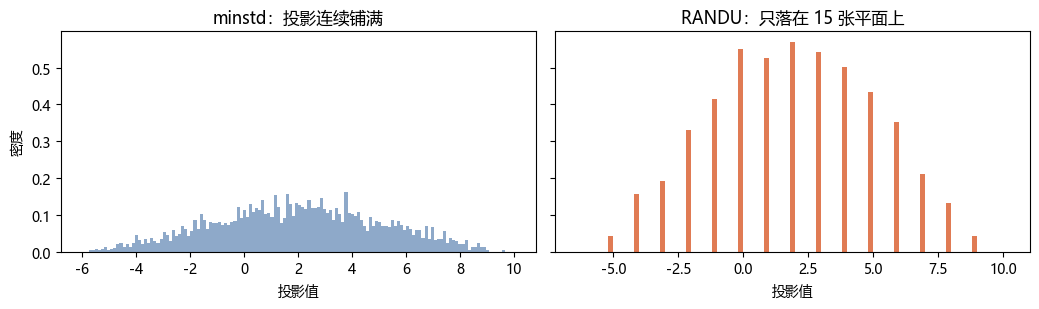

In [11]:
proj_min = 9*u_min[:-2] - 6*u_min[1:-1] + u_min[2:]
proj_ran = 9*u_ran[:-2] - 6*u_ran[1:-1] + u_ran[2:]
cvals = np.round(proj_ran).astype(int)      # m = 2^31 时 u 与投影值都是精确浮点
uvals = np.unique(cvals)
print(f"RANDU 投影 9u_n − 6u_(n+1) + u_(n+2) 的取值集合：{uvals}")
print(f"共 {len(uvals)} 张平面（理论 c ∈ {{−5,…,9}} = 15 张）；minstd 投影铺满连续区间")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2), sharey=True)
ax[0].hist(proj_min, bins=140, range=(-6, 10), density=True, color="#8ea9c9")
ax[0].set_title("minstd：投影连续铺满"); ax[0].set_xlabel("投影值"); ax[0].set_ylabel("密度")
ax[1].hist(proj_ran, bins=np.arange(-6.4, 10.4, 0.2), density=True, color="#e07b54")
ax[1].set_title("RANDU：只落在 15 张平面上"); ax[1].set_xlabel("投影值")
fig.tight_layout(); save(fig, "out-3-5.png"); plt.show()

## 实验 5 Bays–Durham 洗牌：治序列相关，不治值域（D&S §3.6）

RANDU 的最低两位只能在 1↔3 间交替（奇乘子 + 奇种子的必然结果）：当硬币用永远出同一面系、且相邻两次必然不同。
用 Bays–Durham 洗牌（97 项的表）重排输出：**相邻相关性被打散，但"只出奇数"的值域缺陷还在**——洗牌重排值，不创造新值。

In [12]:
def bays_durham(a, m, seed, k=97, n=20000):
    """Bays–Durham 洗牌输出流 y（D&S §3.6 的 6 步算法）"""
    x = seed
    T = np.empty(k, dtype=np.int64)
    for j in range(k):                 # 1. 用 x_1..x_k 填表
        x = (a * x) % m
        T[j] = x
    x = (a * x) % m                    # x_{k+1} 作为第一个输出
    y = np.empty(n, dtype=np.int64)
    y[0] = x
    for i in range(1, n):
        j = (k * y[i-1]) // m          # 2. 表指针由上一个输出 y_{i-1} 决定
        y[i] = T[j]                    # 4. 输出表项
        x = (a * x) % m                # 5. 取下一个原始数补进表
        T[j] = x
    return y

xint = (lcg_u(65539, 2**31, 1, 20000) * 2**31).astype(np.int64)   # 原始 RANDU 整数流
yint = bays_durham(65539, 2**31, 1, k=97, n=20000)                # 洗牌后

for name, arr in [("直接 RANDU", xint), ("洗牌后  ", yint)]:
    low2 = arr % 4
    cnt = np.bincount(low2, minlength=4)
    V = float(((cnt - len(arr)/4)**2 / (len(arr)/4)).sum())
    coin = (low2 == 1).astype(int)          # 1→正面, 3→反面
    same = float(np.mean(coin[1:] == coin[:-1]))
    print(f"{name}: 低两位取值 {np.unique(low2)}, 卡方(4类) V = {V:.0f}, "
          f"相邻同面频率 = {same:.4f}（理论 0.5）")

直接 RANDU: 低两位取值 [1 3], 卡方(4类) V = 20000, 相邻同面频率 = 0.0000（理论 0.5）
洗牌后  : 低两位取值 [1 3], 卡方(4类) V = 20000, 相邻同面频率 = 0.4990（理论 0.5）


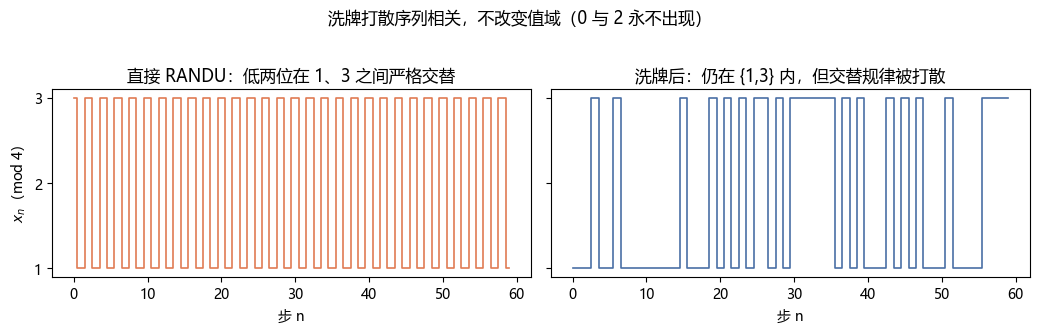

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2), sharey=True)
ax[0].step(range(60), xint[:60] % 4, where="mid", lw=1.2, color="#e07b54")
ax[0].set_yticks([0, 1, 2, 3]); ax[0].set_title("直接 RANDU：低两位在 1、3 之间严格交替")
ax[0].set_xlabel("步 n"); ax[0].set_ylabel("$x_n$（mod 4）")
ax[1].step(range(60), yint[:60] % 4, where="mid", lw=1.2, color="#4a6fa5")
ax[1].set_title("洗牌后：仍在 {1,3} 内，但交替规律被打散")
ax[1].set_xlabel("步 n")
fig.suptitle("洗牌打散序列相关，不改变值域（0 与 2 永不出现）", y=1.03)
fig.tight_layout(); save(fig, "out-3-6.png"); plt.show()

## 实验 6 Wichmann–Hill 组合生成器（D&S §3.8.2）

三个小 LCG 各自满周期（30268 / 30306 / 30322），组合 $\rho=(x/30269+y/30307+z/30323) \bmod 1$，周期 = 三者的最小公倍数 ≈ $7\times10^{12}$。验证子周期、组合周期，并做均匀性快查。

In [14]:
def wichmann_hill(n, seeds=(123, 456, 789)):
    x, y, z = seeds
    out = np.empty(n)
    for i in range(n):
        x = (171 * x) % 30269
        y = (172 * y) % 30307
        z = (170 * z) % 30323
        out[i] = (x/30269 + y/30307 + z/30323) % 1.0
    return out

for a, m in [(171, 30269), (172, 30307), (170, 30323)]:
    print(f"子生成器 a={a}, m={m}: 周期 = {lcg_period(a, 0, m, 1)}（= m−1，满周期）")
print("组合周期 = lcm(30268, 30306, 30322) =", math.lcm(30268, 30306, 30322))

uwh = wichmann_hill(100_000)
cnt = np.histogram(uwh, bins=20, range=(0, 1))[0]
_, p_chi = stats.chisquare(cnt)
print(f"10 万个数：均值 {uwh.mean():.4f}（理论 0.5），方差 {uwh.var():.5f}（理论 1/12 = {1/12:.5f}）；"
      f"卡方(20 bins) p 值 = {p_chi:.3f}")

子生成器 a=171, m=30269: 周期 = 30268（= m−1，满周期）
子生成器 a=172, m=30307: 周期 = 30306（= m−1，满周期）
子生成器 a=170, m=30323: 周期 = 30322（= m−1，满周期）
组合周期 = lcm(30268, 30306, 30322) = 6953607871644
10 万个数：均值 0.5004（理论 0.5），方差 0.08324（理论 1/12 = 0.08333）；卡方(20 bins) p 值 = 0.459


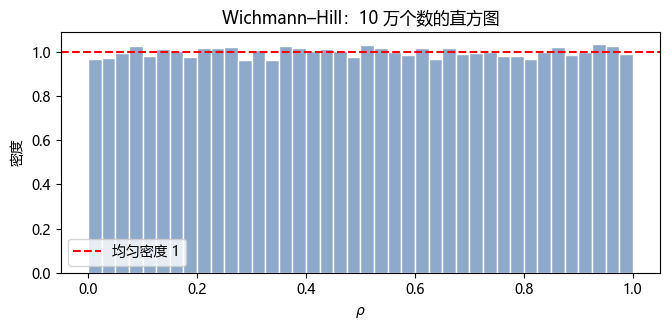

In [15]:
fig, ax = plt.subplots(figsize=(6.8, 3.4))
ax.hist(uwh, bins=40, density=True, color="#8ea9c9", edgecolor="white")
ax.axhline(1.0, color="r", ls="--", lw=1.5, label="均匀密度 1")
ax.set_xlabel("$\\rho$"); ax.set_ylabel("密度")
ax.set_title("Wichmann–Hill：10 万个数的直方图")
ax.legend()
fig.tight_layout(); save(fig, "out-3-7.png"); plt.show()

## 实验 7 统计检验复习：卡方 + KS（S&M 附录 A + D&S §3.4.4）

- **卡方拟合优度**：$V=\sum_i (Y_i - p_i N)^2/(p_i N)$，自由度 $k-1$；$V$ 大 = 与均匀矛盾。
- **KS 检验**：$D_N = \sup_t |\hat F_N(t) - F(t)|$，$n>45$ 时 5% 临界值 $1.36/\sqrt{n}$。

先复现 S&M 附录 A 的三例 LCG（$x_{n+1}=1+3x_n \bmod p$，种子 3，抽 1000 个数），再用卡方 + KS 对 PCG64 / minstd / RANDU 各测一次——注意基本检验**查不出** RANDU 的三维缺陷。

In [16]:
def lcg_norm(a, c, m, seed, n):
    x, out = seed, np.empty(n)
    for i in range(n):
        x = (a * x + c) % m
        out[i] = x / m
    return out

thr = 1.36 / math.sqrt(1000)
print(f"KS 5% 临界值 = {thr:.4f}（S&M 书中参考值：0.3454 / 0.1461 / 0.0241）")
ks_results = {}
for p in (11, 229, 104729):
    u = lcg_norm(3, 1, p, 3, 1000)
    D, pks = stats.kstest(u, "uniform")
    ks_results[p] = u
    print(f"p = {p:6d}: D_1000 = {D:.4f}（{'不通过' if D > thr else '通过'}，p 值 = {pks:.2e}）")

KS 5% 临界值 = 0.0430（S&M 书中参考值：0.3454 / 0.1461 / 0.0241）
p =     11: D_1000 = 0.3455（不通过，p 值 = 4.22e-107）
p =    229: D_1000 = 0.0904（不通过，p 值 = 1.44e-07）
p = 104729: D_1000 = 0.0355（通过，p 值 = 1.56e-01）


In [17]:
print(f"{'生成器':>8} | 卡方 p 值(20 bins, n=10^4) | KS p 值(n=10^4)")
for name, u in [("PCG64", rng.random(10_000)),
                ("minstd", lcg_norm(16807, 0, 2**31 - 1, 123, 10_000)),
                ("RANDU", lcg_norm(65539, 0, 2**31, 1, 10_000))]:
    cnt = np.histogram(u, bins=20, range=(0, 1))[0]
    _, p_chi = stats.chisquare(cnt)
    _, p_ks = stats.kstest(u, "uniform")
    print(f"{name:>8} | {p_chi:^24.3f} | {p_ks:.3f}")
print("p 值小（<0.05）= 与均匀显著矛盾；p 大 = 没查出问题 ≠ 证明随机（RANDU 就是反例）")

     生成器 | 卡方 p 值(20 bins, n=10^4) | KS p 值(n=10^4)
   PCG64 |          0.242           | 0.927
  minstd |          0.094           | 0.152
   RANDU |          0.712           | 0.811
p 值小（<0.05）= 与均匀显著矛盾；p 大 = 没查出问题 ≠ 证明随机（RANDU 就是反例）


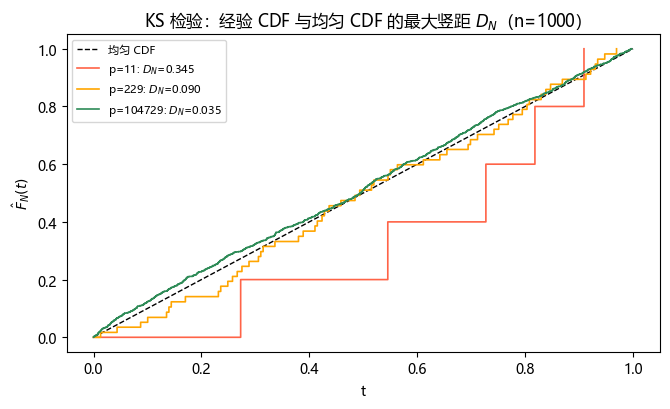

In [18]:
fig, ax = plt.subplots(figsize=(6.8, 4.2))
tt = np.linspace(0, 1, 500)
ax.plot(tt, tt, "k--", lw=1, label="均匀 CDF")
for p, c in [(11, "tomato"), (229, "orange"), (104729, "seagreen")]:
    u = np.sort(ks_results[p])
    Nn = len(u)
    Fh = np.arange(1, Nn + 1) / Nn
    D = max(np.abs(np.concatenate([[0], Fh]) - np.concatenate([u, [1]])))
    ax.step(np.concatenate([[0], u]), np.concatenate([[0], Fh]), where="post",
            lw=1.2, color=c, label=f"p={p}: $D_N$={D:.3f}")
ax.set_xlabel("t"); ax.set_ylabel("$\\hat F_N(t)$")
ax.set_title("KS 检验：经验 CDF 与均匀 CDF 的最大竖距 $D_N$（n=1000）")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); save(fig, "out-3-8.png"); plt.show()